In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración visual
sns.set_theme(style="whitegrid")

# Buscar archivo
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

df = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

# Separar particiones
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

print("Dataset cargado correctamente")
print("Total de registros:", len(df))
print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Prueba:", len(test))

print("\nColumnas disponibles:")
print(df.columns.tolist())

Dataset cargado correctamente
Total de registros: 5000
Entrenamiento: 3752
Validación: 624
Prueba: 624

Columnas disponibles:
['id_hallazgo', 'id_auditoria', 'fecha_auditoria', 'empresa', 'area', 'tipo_auditoria', 'hallazgo', 'categoria_id', 'categoria', 'criterio_evaluacion', 'clasificacion', 'nivel_riesgo', 'estado', 'responsable_area', 'fecha_cierre', 'origen_dato', 'escenario_id', 'split']


In [3]:
resumen = df.groupby("categoria").agg(
    registros=("hallazgo", "count"),
    escenarios=("escenario_id", "nunique"),
    textos_unicos=("hallazgo", "nunique")
)

resumen["registros_por_escenario"] = (
    resumen["registros"] / resumen["escenarios"]
).round(2)

resumen = resumen.sort_values(
    "escenarios",
    ascending=False
)

display(resumen)

,registros,escenarios,textos_unicos,registros_por_escenario
categoria,,,,
Condiciones locativas,417,8,281,52.12
Control documental SG-SST,416,8,280,52.00
Elementos de proteccion personal,417,8,288,52.12
Formacion y competencias SST,417,8,281,52.12
Gestion SST de contratistas,416,8,280,52.00
Gestion de sustancias quimicas,417,8,288,52.12
Identificacion de peligros y valoracion de riesgos,416,8,288,52.00
Inspecciones y mantenimiento,417,8,280,52.12
Investigacion de incidentes y accidentes,416,8,288,52.00


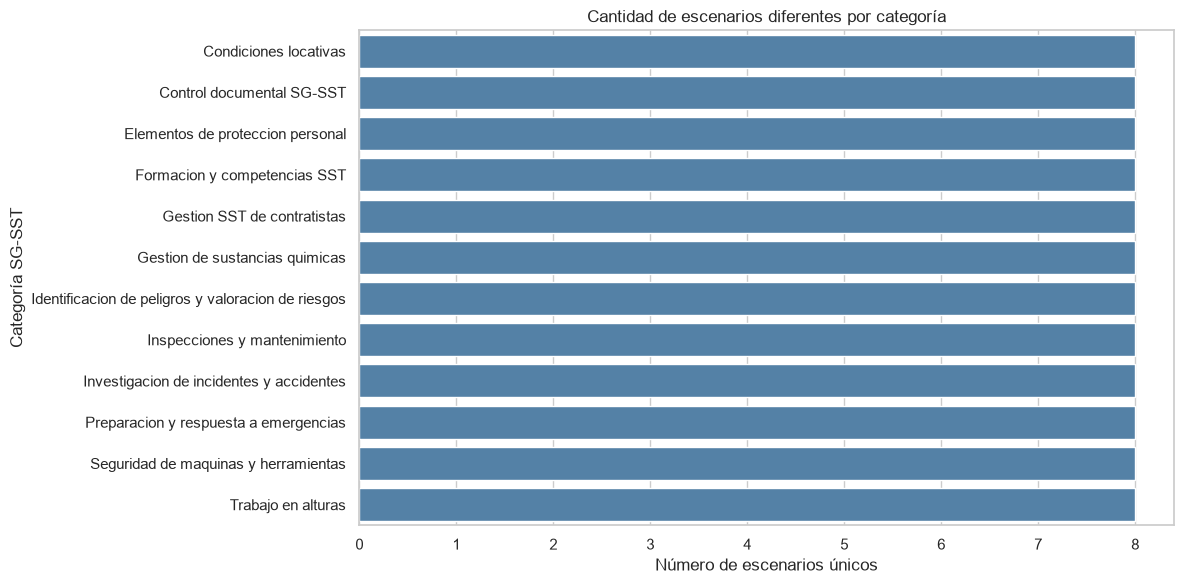

In [4]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=resumen.reset_index(),
    x="escenarios",
    y="categoria",
    color="steelblue"
)

plt.title("Cantidad de escenarios diferentes por categoría")
plt.xlabel("Número de escenarios únicos")
plt.ylabel("Categoría SG-SST")

plt.tight_layout()
plt.show()

In [5]:
tabla_escenarios = pd.crosstab(
    df["categoria"],
    df["split"],
    values=df["escenario_id"],
    aggfunc="nunique"
).fillna(0).astype(int)

display(tabla_escenarios)

# Comprobar escenarios compartidos
esc_train = set(train["escenario_id"])
esc_val = set(val["escenario_id"])
esc_test = set(test["escenario_id"])

print("\nEscenarios compartidos:")
print("Train - Val:", len(esc_train & esc_val))
print("Train - Test:", len(esc_train & esc_test))
print("Val - Test:", len(esc_val & esc_test))

split,test,train,val
categoria,,,
Condiciones locativas,1,6,1
Control documental SG-SST,1,6,1
Elementos de proteccion personal,1,6,1
Formacion y competencias SST,1,6,1
Gestion SST de contratistas,1,6,1
Gestion de sustancias quimicas,1,6,1
Identificacion de peligros y valoracion de riesgos,1,6,1
Inspecciones y mantenimiento,1,6,1
Investigacion de incidentes y accidentes,1,6,1



Escenarios compartidos:
Train - Val: 0
Train - Test: 0
Val - Test: 0


In [6]:
total = len(df)

textos_unicos = df["hallazgo"].nunique()

repetidos = total - textos_unicos

porcentaje = repetidos / total * 100

print("Total de registros:", total)
print("Textos únicos:", textos_unicos)
print("Repeticiones adicionales:", repetidos)

print(
    "Porcentaje de repeticiones:",
    round(porcentaje, 2),
    "%"
)

print("\nHallazgos más frecuentes:")

display(
    df["hallazgo"].value_counts().head(10)
)

Total de registros: 5000
Textos únicos: 3396
Repeticiones adicionales: 1604
Porcentaje de repeticiones: 32.08 %

Hallazgos más frecuentes:


hallazgo
La muestra revisada revelo que un incidente sin lesion no fue reportado; el hecho continua pendiente de analisis.                5
Al contrastar la practica con el control previsto, se encontro que no se entregaron gafas de seguridad al personal de corte.     5
Se identifico una desviacion durante la visita: la lista de chequeo tiene hallazgos sin seguimiento.                             5
Se identifico una desviacion durante la visita: una recomendacion de inspeccion permanece abierta.                               5
El responsable del proceso informo que el borde expuesto carece de proteccion colectiva, sin aportar soporte de correccion.      5
La muestra revisada revelo que no se puede recuperar la evidencia solicitada; el hecho continua pendiente de analisis.           5
Al contrastar la practica con el control previsto, se encontro que no se realizo coordinacion SST de actividades simultaneas.    5
Se identifico una desviacion durante la visita: la herramienta manual pres

In [7]:
# Obtener un ejemplo de cada escenario
ejemplos_escenarios = (
    df.groupby(
        ["categoria", "split", "escenario_id"],
        as_index=False
    )
    .agg(
        ejemplo_hallazgo=("hallazgo", "first"),
        cantidad_registros=("hallazgo", "size")
    )
)

display(
    ejemplos_escenarios.sort_values(
        ["categoria", "split", "escenario_id"]
    )
)

,categoria,split,escenario_id,ejemplo_hallazgo,cantidad_registros
0,Condiciones locativas,test,LOCATIVOS-05,En el registro de control de el centro de dist...,52
1,Condiciones locativas,train,LOCATIVOS-00,Durante el recorrido se evidencio que hay mate...,53
2,Condiciones locativas,train,LOCATIVOS-01,En la verificacion realizada en la planta de p...,52
3,Condiciones locativas,train,LOCATIVOS-02,"Segun la inspeccion realizada, se observaron c...",52
4,Condiciones locativas,train,LOCATIVOS-04,El equipo auditor documento la siguiente situa...,52
...,...,...,...,...,...
91,Trabajo en alturas,train,ALTURAS-04,"Segun la inspeccion realizada, el trabajador n...",52
92,Trabajo en alturas,train,ALTURAS-05,"Segun la inspeccion realizada, no se inspeccio...",52
93,Trabajo en alturas,train,ALTURAS-06,La muestra revisada revelo que la escalera de ...,52
94,Trabajo en alturas,train,ALTURAS-07,Al contrastar la practica con el control previ...,52


In [8]:
# Normalizar textos para comparar
def normalizar(textos):
    return set(
        textos.str.lower().str.strip()
    )

textos_train = normalizar(train["hallazgo"])
textos_val = normalizar(val["hallazgo"])
textos_test = normalizar(test["hallazgo"])

print("Textos idénticos entre particiones:\n")

print(
    "Train - Val:",
    len(textos_train & textos_val)
)

print(
    "Train - Test:",
    len(textos_train & textos_test)
)

print(
    "Val - Test:",
    len(textos_val & textos_test)
)

Textos idénticos entre particiones:

Train - Val: 0
Train - Test: 0
Val - Test: 0


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Convertir los textos a vectores TF-IDF
vectorizador = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True
)

X_train_tfidf = vectorizador.fit_transform(
    train["hallazgo"]
)

X_val_tfidf = vectorizador.transform(
    val["hallazgo"]
)

# Similitud entre validación y entrenamiento
similitudes = cosine_similarity(
    X_val_tfidf,
    X_train_tfidf
)

# Encontrar el antecedente más parecido
indices = similitudes.argmax(axis=1)

analisis = pd.DataFrame({
    "hallazgo_validacion": val["hallazgo"].to_numpy(),
    "categoria_real": val["categoria"].to_numpy(),
    "escenario_validacion": val["escenario_id"].to_numpy(),
    "hallazgo_similar": train.iloc[indices]["hallazgo"].to_numpy(),
    "categoria_similar": train.iloc[indices]["categoria"].to_numpy(),
    "similitud": similitudes.max(axis=1)
})

analisis["misma_categoria"] = (
    analisis["categoria_real"] ==
    analisis["categoria_similar"]
)

print(
    "Similitud promedio:",
    round(analisis["similitud"].mean(), 4)
)

print(
    "Antecedentes más parecidos de la misma categoría:",
    round(analisis["misma_categoria"].mean() * 100, 2),
    "%"
)

display(
    analisis[
        ~analisis["misma_categoria"]
    ].head(15)
)

Similitud promedio: 0.6296
Antecedentes más parecidos de la misma categoría: 6.89 %


,hallazgo_validacion,categoria_real,escenario_validacion,hallazgo_similar,categoria_similar,similitud,misma_categoria
0,En entrevista y observacion directa se advirti...,Formacion y competencias SST,FORMACION-04,En entrevista y observacion directa se advirti...,Preparacion y respuesta a emergencias,0.581945,False
1,El equipo auditor documento la siguiente situa...,Identificacion de peligros y valoracion de rie...,RIESGOS-05,El equipo auditor documento la siguiente situa...,Trabajo en alturas,0.610529,False
2,Se identifico una desviacion durante la visita...,Elementos de proteccion personal,EPP-06,Se identifico una desviacion durante la visita...,Identificacion de peligros y valoracion de rie...,0.557293,False
3,El responsable del proceso informo que el mant...,Inspecciones y mantenimiento,INSPECCIONES-02,El responsable del proceso informo que el piso...,Condiciones locativas,0.607172,False
4,La muestra revisada revelo que la reinduccion ...,Formacion y competencias SST,FORMACION-04,La muestra revisada revelo que se modifico el ...,Identificacion de peligros y valoracion de rie...,0.595419,False
5,El equipo auditor documento la siguiente situa...,Gestion SST de contratistas,CONTRATISTAS-03,El equipo auditor documento la siguiente situa...,Gestion de sustancias quimicas,0.647304,False
6,"Segun la inspeccion realizada, se hallo un pun...",Trabajo en alturas,ALTURAS-01,"Segun la inspeccion realizada, ingreso un subc...",Gestion SST de contratistas,0.661829,False
7,La muestra revisada revelo que no se definiero...,Gestion SST de contratistas,CONTRATISTAS-03,La muestra revisada revelo que no se puede rec...,Control documental SG-SST,0.647141,False
8,La evidencia recopilada permite establecer que...,Trabajo en alturas,ALTURAS-01,La evidencia recopilada permite establecer que...,Preparacion y respuesta a emergencias,0.645012,False
9,El responsable del proceso informo que se enco...,Elementos de proteccion personal,EPP-06,El responsable del proceso informo que el bord...,Trabajo en alturas,0.566534,False


In [10]:
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from sklearn.preprocessing import LabelEncoder
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else "cpu"

# Localizar carpeta del modelo
ruta_modelo = Path("models/minilm_sst_finetuned")

if not ruta_modelo.exists():
    ruta_modelo = Path("../models/minilm_sst_finetuned")

modelo_id = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

# Cargar tokenizador
tokenizer = AutoTokenizer.from_pretrained(ruta_modelo)

# Recuperar codificación de categorías
encoder = LabelEncoder()
encoder.fit(train["categoria"])

num_clases = len(encoder.classes_)

# Reconstruir la arquitectura
class MiniLMClasificador(nn.Module):

    def __init__(self, transformer, num_clases):
        super().__init__()

        self.transformer = transformer
        self.dropout = nn.Dropout(0.2)

        self.clasificador = nn.Linear(
            transformer.config.hidden_size,
            num_clases
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.transformer(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        tokens = outputs.last_hidden_state

        mascara = attention_mask.unsqueeze(-1)

        embeddings = (
            (tokens * mascara).sum(dim=1)
            / mascara.sum(dim=1).clamp(min=1)
        )

        embeddings = self.dropout(embeddings)

        return self.clasificador(embeddings)


transformer = AutoModel.from_pretrained(modelo_id)

modelo_sst = MiniLMClasificador(
    transformer,
    num_clases
)

# Recuperar pesos entrenados
pesos = torch.load(
    ruta_modelo / "modelo_sst.pth",
    map_location="cpu",
    weights_only=True
)

modelo_sst.load_state_dict(pesos)
modelo_sst = modelo_sst.to(device)

modelo_sst.eval()

print("MiniLM ajustado recuperado correctamente")
print("Dispositivo:", device)
print("Categorías:", num_clases)

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1932.12it/s]


MiniLM ajustado recuperado correctamente
Dispositivo: cuda
Categorías: 12


In [11]:
import numpy as np

MAX_LENGTH = 48
BATCH_SIZE = 16

textos = val["hallazgo"].tolist()

predicciones = []
confianzas = []

modelo_sst.eval()

with torch.inference_mode():

    for inicio in range(0, len(textos), BATCH_SIZE):

        lote_textos = textos[
            inicio:inicio + BATCH_SIZE
        ]

        tokens = tokenizer(
            lote_textos,
            truncation=True,
            padding=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        tokens = {
            k: v.to(device)
            for k, v in tokens.items()
        }

        logits = modelo_sst(
            input_ids=tokens["input_ids"],
            attention_mask=tokens["attention_mask"]
        )

        probabilidades = torch.softmax(
            logits,
            dim=1
        )

        confianza, indices = probabilidades.max(
            dim=1
        )

        predicciones.extend(
            indices.cpu().numpy()
        )

        confianzas.extend(
            confianza.cpu().numpy()
        )

# Crear tabla de resultados
resultados_val = val[
    ["hallazgo", "categoria", "escenario_id"]
].copy()

resultados_val["categoria_predicha"] = (
    encoder.inverse_transform(predicciones)
)

resultados_val["confianza"] = confianzas

resultados_val["correcto"] = (
    resultados_val["categoria"]
    == resultados_val["categoria_predicha"]
)

print("Registros evaluados:", len(resultados_val))

print(
    "Accuracy:",
    round(resultados_val["correcto"].mean(), 4)
)

display(resultados_val.head(10))

Registros evaluados: 624
Accuracy: 0.5785


,hallazgo,categoria,escenario_id,categoria_predicha,confianza,correcto
9,En entrevista y observacion directa se advirti...,Formacion y competencias SST,FORMACION-04,Condiciones locativas,0.946999,False
11,El equipo auditor documento la siguiente situa...,Identificacion de peligros y valoracion de rie...,RIESGOS-05,Formacion y competencias SST,0.928279,False
12,Se identifico una desviacion durante la visita...,Elementos de proteccion personal,EPP-06,Elementos de proteccion personal,0.801706,True
38,El responsable del proceso informo que el mant...,Inspecciones y mantenimiento,INSPECCIONES-02,Seguridad de maquinas y herramientas,0.961229,False
44,La muestra revisada revelo que la reinduccion ...,Formacion y competencias SST,FORMACION-04,Condiciones locativas,0.948075,False
56,El equipo auditor documento la siguiente situa...,Gestion SST de contratistas,CONTRATISTAS-03,Gestion SST de contratistas,0.339292,True
58,"Segun la inspeccion realizada, se hallo un pun...",Trabajo en alturas,ALTURAS-01,Inspecciones y mantenimiento,0.961489,False
62,La muestra revisada revelo que no se definiero...,Gestion SST de contratistas,CONTRATISTAS-03,Gestion SST de contratistas,0.445710,True
69,La evidencia recopilada permite establecer que...,Trabajo en alturas,ALTURAS-01,Inspecciones y mantenimiento,0.966482,False
80,El responsable del proceso informo que se enco...,Elementos de proteccion personal,EPP-06,Elementos de proteccion personal,0.600030,True


In [12]:
# Seleccionar predicciones incorrectas
errores = resultados_val[
    ~resultados_val["correcto"]
].copy()

# Agrupar errores
confusiones = (
    errores.groupby(
        ["categoria", "categoria_predicha"]
    )
    .size()
    .reset_index(name="cantidad")
    .sort_values(
        "cantidad",
        ascending=False
    )
)

print("Total de errores:", len(errores))

print("\nConfusiones más frecuentes:")

display(confusiones.head(15))

Total de errores: 263

Confusiones más frecuentes:


,categoria,categoria_predicha,cantidad
0,Condiciones locativas,Gestion de sustancias quimicas,52
1,Formacion y competencias SST,Condiciones locativas,52
3,Identificacion de peligros y valoracion de rie...,Formacion y competencias SST,52
4,Inspecciones y mantenimiento,Seguridad de maquinas y herramientas,52
5,Trabajo en alturas,Inspecciones y mantenimiento,52
2,Gestion SST de contratistas,Formacion y competencias SST,3


In [13]:
resumen_escenarios = (
    resultados_val.groupby(
        ["categoria", "escenario_id"]
    )
    .agg(
        total=("correcto", "size"),
        aciertos=("correcto", "sum"),
        confianza_promedio=("confianza", "mean")
    )
    .reset_index()
)

resumen_escenarios["accuracy"] = (
    resumen_escenarios["aciertos"]
    / resumen_escenarios["total"]
)

resumen_escenarios = resumen_escenarios.sort_values(
    "accuracy",
    ascending=True
)

display(resumen_escenarios)

,categoria,escenario_id,total,aciertos,confianza_promedio,accuracy
0,Condiciones locativas,LOCATIVOS-03,52,0,0.902861,0.000000
3,Formacion y competencias SST,FORMACION-04,52,0,0.944947,0.000000
6,Identificacion de peligros y valoracion de rie...,RIESGOS-05,52,0,0.952511,0.000000
7,Inspecciones y mantenimiento,INSPECCIONES-02,52,0,0.965186,0.000000
11,Trabajo en alturas,ALTURAS-01,52,0,0.953781,0.000000
4,Gestion SST de contratistas,CONTRATISTAS-03,52,49,0.447490,0.942308
2,Elementos de proteccion personal,EPP-06,52,52,0.715049,1.000000
1,Control documental SG-SST,DOCUMENTAL-06,52,52,0.822118,1.000000
5,Gestion de sustancias quimicas,QUIMICOS-02,52,52,0.962317,1.000000
8,Investigacion de incidentes y accidentes,INCIDENTES-02,52,52,0.953598,1.000000


In [14]:
errores_confiados = errores.sort_values(
    "confianza",
    ascending=False
)

columnas = [
    "hallazgo",
    "categoria",
    "categoria_predicha",
    "confianza",
    "escenario_id"
]

print("Errores con mayor confianza:")

display(
    errores_confiados[columnas].head(20)
)

Errores con mayor confianza:


,hallazgo,categoria,categoria_predicha,confianza,escenario_id
3605,El equipo auditor documento la siguiente situa...,Trabajo en alturas,Inspecciones y mantenimiento,0.970920,ALTURAS-01
1724,El equipo auditor documento la siguiente situa...,Trabajo en alturas,Inspecciones y mantenimiento,0.970920,ALTURAS-01
1668,El equipo auditor documento la siguiente situa...,Trabajo en alturas,Inspecciones y mantenimiento,0.970920,ALTURAS-01
3051,El equipo auditor documento la siguiente situa...,Trabajo en alturas,Inspecciones y mantenimiento,0.970920,ALTURAS-01
3197,El equipo auditor documento la siguiente situa...,Trabajo en alturas,Inspecciones y mantenimiento,0.970920,ALTURAS-01
3250,En entrevista y observacion directa se advirti...,Trabajo en alturas,Inspecciones y mantenimiento,0.970099,ALTURAS-01
3825,En la verificacion realizada en el centro de d...,Inspecciones y mantenimiento,Seguridad de maquinas y herramientas,0.969954,INSPECCIONES-02
2552,En entrevista y observacion directa se advirti...,Inspecciones y mantenimiento,Seguridad de maquinas y herramientas,0.969893,INSPECCIONES-02
118,Durante el recorrido se evidencio que se hallo...,Trabajo en alturas,Inspecciones y mantenimiento,0.969573,ALTURAS-01
711,En el registro de control de el area de servic...,Inspecciones y mantenimiento,Seguridad de maquinas y herramientas,0.969544,INSPECCIONES-02


In [15]:
from pathlib import Path

ruta_resultados = Path("resultados")

if not Path("data").exists():
    ruta_resultados = Path("../resultados")

ruta_resultados.mkdir(parents=True, exist_ok=True)

# Guardar predicciones de validación
resultados_val.to_csv(
    ruta_resultados / "06_predicciones_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar confusiones
confusiones.to_csv(
    ruta_resultados / "06_confusiones.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar rendimiento por escenario
resumen_escenarios.to_csv(
    ruta_resultados / "06_rendimiento_escenarios.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Análisis del notebook 06 guardado correctamente.")

Análisis del notebook 06 guardado correctamente.
